# Stage 2 — EDA: Singapore Commercial Bank Loans To Residents By Industry

**Project:** Singapore Banking Loan Portfolio & Sector Exposure Analytics

**Data source:** PRIMARY dataset only — `data/processed/loan_balances_long.csv` and
`data/processed/loan_categories.csv`, produced by `scripts/clean_data.py` from the
official data.gov.sg dataset `d_af0415517a3a3a94b3b74039934ef976`
("Commercial Banks: Loans And Advances To Residents By Industry"). See
`docs/STAGE_1_DATA_INSPECTION.md` and `docs/STAGE_2_FINDINGS.md` for provenance,
hierarchy, and validation details. The Supporting dataset is not used here.

**Important framing for every result below:**
- All balances are **end-of-period stock balances** (S$ million), not flows. An
  increase in a balance is never described as "new loans originated."
- Balances are never summed across months.
- Sector/category shares always use the dataset's own reported parent total as the
  denominator (e.g. a business sector's share of *Loans To Businesses - Total*),
  never an ad-hoc sum of siblings.
- Parent totals and their own children are never added together.
- Findings are descriptive. No causal claims are made about interest rates,
  monetary policy, or macroeconomic events, and no claims are made about default
  risk, profitability, or credit quality — this dataset cannot establish those.
- Sector definitions are exactly as published in the official dataset.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# Resolve project root whether this notebook is executed from the notebooks/
# directory (the normal case) or from the project root.
if (Path.cwd() / "data").exists():
    ROOT = Path.cwd()
else:
    ROOT = Path.cwd().parent

DATA_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_colwidth", 60)


## 1. Load processed data

Loaded directly from the Stage 2 cleaning script's outputs — nothing here is manually re-entered or reconstructed.

In [2]:
long_df = pd.read_csv(DATA_DIR / "loan_balances_long.csv", parse_dates=["period_end"])
cats = pd.read_csv(DATA_DIR / "loan_categories.csv")

print("loan_balances_long.csv:", long_df.shape)
print("loan_categories.csv:  ", cats.shape)
display(long_df.head())
display(cats.head())


loan_balances_long.csv: (1674, 3)
loan_categories.csv:   (27, 7)


,period_end,series_id,balance_sgd_mn
0,2021-07-31,consumer_loans_housing_and_bridging_loans,208689.3
1,2021-08-31,consumer_loans_housing_and_bridging_loans,209864.4
2,2021-09-30,consumer_loans_housing_and_bridging_loans,211188.6
3,2021-10-31,consumer_loans_housing_and_bridging_loans,212234.2
4,2021-11-30,consumer_loans_housing_and_bridging_loans,213503.6


,series_id,series_name,parent_series_id,indent_level,category_role,is_leaf,row_order
0,total_loans_and_advances_including_bills_financing,Total Loans And Advances Including Bills Financing,NaN,0,total,False,0
1,loans_to_businesses_total,Loans To Businesses - Total,total_loans_and_advances_including_bills_financing,4,business_total,False,1
2,loans_to_businesses_agriculture_mining_and_quarrying_total,"Loans To Businesses - Agriculture, Mining And Quarrying ...",loans_to_businesses_total,8,business_sector,False,2
3,loans_to_businesses_agriculture_mining_and_quarrying_agr...,"Loans To Businesses - Agriculture, Mining And Quarrying ...",loans_to_businesses_agriculture_mining_and_quarrying_total,12,business_subsector,True,3
4,loans_to_businesses_agriculture_mining_and_quarrying_min...,"Loans To Businesses - Agriculture, Mining And Quarrying ...",loans_to_businesses_agriculture_mining_and_quarrying_total,12,business_subsector,True,4


In [3]:
# Wide view: one row per period_end, one column per series_id. Convenience only
# — all validation already happened in scripts/clean_data.py.
wide = long_df.pivot(index="period_end", columns="series_id", values="balance_sgd_mn").sort_index()

print("Periods:", wide.index.min().date(), "to", wide.index.max().date(), f"({len(wide)} months)")
print(cats["category_role"].value_counts())


Periods: 2021-07-31 to 2026-08-31 (62 months)
category_role
business_subsector    11
business_sector        8
consumer_category      5
total                  1
business_total         1
consumer_total         1
Name: count, dtype: int64


## 2. Helper setup

Fixed category lookups (by role, not by row position) and a small chart style
helper so every figure shares the same look. Colors are assigned **by entity**
and reused consistently across charts — never re-assigned by rank — following
a small fixed categorical palette.


In [4]:
name_map = cats.set_index("series_id")["series_name"]

def sid(role):
    """series_id(s) for a given category_role."""
    return cats.loc[cats["category_role"] == role, "series_id"]

TOTAL_ID = sid("total").iloc[0]
BUSINESS_TOTAL_ID = sid("business_total").iloc[0]
CONSUMER_TOTAL_ID = sid("consumer_total").iloc[0]

# Exactly the eight mutually exclusive top-level business sectors (direct
# children of the business total) — not the 11 finer subsector rows beneath them.
BUSINESS_SECTOR_IDS = cats.loc[
    (cats["category_role"] == "business_sector"), "series_id"
].tolist()

# Exactly the five consumer lending categories.
CONSUMER_CATEGORY_IDS = cats.loc[
    cats["category_role"] == "consumer_category", "series_id"
].tolist()

assert len(BUSINESS_SECTOR_IDS) == 8, f"expected 8 business sectors, got {len(BUSINESS_SECTOR_IDS)}"
assert len(CONSUMER_CATEGORY_IDS) == 5, f"expected 5 consumer categories, got {len(CONSUMER_CATEGORY_IDS)}"

FIRST_PERIOD = wide.index.min()
LATEST_PERIOD = wide.index.max()
PRIOR_12M = LATEST_PERIOD - pd.DateOffset(months=12)
assert PRIOR_12M in wide.index, "12-months-prior period not found in the dataset"

print("First period: ", FIRST_PERIOD.date())
print("Latest period:", LATEST_PERIOD.date())
print("12m-prior:    ", PRIOR_12M.date())


First period:  2021-07-31
Latest period: 2026-08-31
12m-prior:     2025-08-31


In [5]:
def safe_pct_change(new, old):
    """Percentage change that returns NaN instead of dividing by zero."""
    new = np.asarray(new, dtype=float)
    old = np.asarray(old, dtype=float)
    with np.errstate(divide="ignore", invalid="ignore"):
        result = np.where(old == 0, np.nan, (new - old) / old * 100)
    return result

# --- Chart style (static matplotlib charts; light surface only) ---
INK_PRIMARY = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRIDLINE = "#e1e0d9"
SURFACE = "#fcfcfb"

# Fixed categorical palette (validated for CVD-safe adjacent contrast),
# assigned once per entity below and reused across all charts.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#4a3aa7", "#e34948"]

GOOD_BLUE = "#2a78d6"   # increase / later period
BAD_RED = "#e34948"     # decrease
PERIOD_COLORS = {"first": "#2a78d6", "latest": "#eb6834"}

# One fixed color per business sector, in the sector's original dataset order
# — reused identically across every chart that shows sectors individually.
SECTOR_COLOR = {
    s: PALETTE[i % len(PALETTE)]
    for i, s in enumerate(cats.loc[cats["series_id"].isin(BUSINESS_SECTOR_IDS)]
                          .sort_values("row_order")["series_id"])
}

def style_ax(ax, title, xlabel=None, ylabel=None):
    ax.set_facecolor(SURFACE)
    # Centered on the whole figure (not just the axes box), so long titles on
    # horizontal bar charts with wide left-side tick labels never clip at the
    # right edge of the figure.
    ax.figure.suptitle(title, color=INK_PRIMARY, fontsize=13, fontweight="bold", y=0.98)
    if xlabel:
        ax.set_xlabel(xlabel, color=INK_SECONDARY, fontsize=10)
    if ylabel:
        ax.set_ylabel(ylabel, color=INK_SECONDARY, fontsize=10)
    ax.tick_params(colors=INK_MUTED, labelsize=9)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    for spine in ("left", "bottom"):
        ax.spines[spine].set_color(INK_MUTED)
    ax.grid(axis="x", color=GRIDLINE, linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)

def short_sector_label(series_id):
    """Shorten 'Loans To Businesses - X - Total' style labels for axis ticks."""
    name = name_map[series_id]
    name = name.replace("Loans To Businesses - ", "")
    name = name.replace(" - Total", "")
    return name

def short_consumer_label(series_id):
    name = name_map[series_id]
    name = name.replace("Consumer Loans - Natural Persons - ", "")
    name = name.replace("Consumer Loans - ", "")
    return name


## Q1 — Total, business, and consumer lending trends (Jul 2021 – Aug 2026)

How have total outstanding loans and the business-vs-consumer mix evolved?


In [6]:
total_series = wide[TOTAL_ID]
biz_series = wide[BUSINESS_TOTAL_ID]
cons_series = wide[CONSUMER_TOTAL_ID]

total_first, total_latest = total_series.loc[FIRST_PERIOD], total_series.loc[LATEST_PERIOD]
biz_share_first = biz_series.loc[FIRST_PERIOD] / total_first * 100
biz_share_latest = biz_series.loc[LATEST_PERIOD] / total_latest * 100
cons_share_first = cons_series.loc[FIRST_PERIOD] / total_first * 100
cons_share_latest = cons_series.loc[LATEST_PERIOD] / total_latest * 100

mom_change_latest = total_series.loc[LATEST_PERIOD] - total_series.loc[wide.index[-2]]
yoy_abs_total = total_series.loc[LATEST_PERIOD] - total_series.loc[PRIOR_12M]
yoy_pct_total = safe_pct_change(total_series.loc[LATEST_PERIOD], total_series.loc[PRIOR_12M])

print(f"Total loans: {FIRST_PERIOD.date()} = S${total_first:,.1f}M  ->  {LATEST_PERIOD.date()} = S${total_latest:,.1f}M")
print(f"Business share of total: {biz_share_first:.2f}% -> {biz_share_latest:.2f}%")
print(f"Consumer share of total: {cons_share_first:.2f}% -> {cons_share_latest:.2f}%")
print(f"Latest month-over-month change in total loans: S${mom_change_latest:,.1f}M "
      f"({wide.index[-2].date()} -> {LATEST_PERIOD.date()})")
print(f"Latest 12-month change in total loans: S${yoy_abs_total:,.1f}M ({yoy_pct_total:.2f}%)")


Total loans: 2021-07-31 = S$793,275.6M  ->  2026-08-31 = S$966,432.7M
Business share of total: 62.02% -> 60.22%
Consumer share of total: 37.98% -> 39.78%
Latest month-over-month change in total loans: S$27,374.2M (2026-07-31 -> 2026-08-31)
Latest 12-month change in total loans: S$114,706.7M (13.47%)


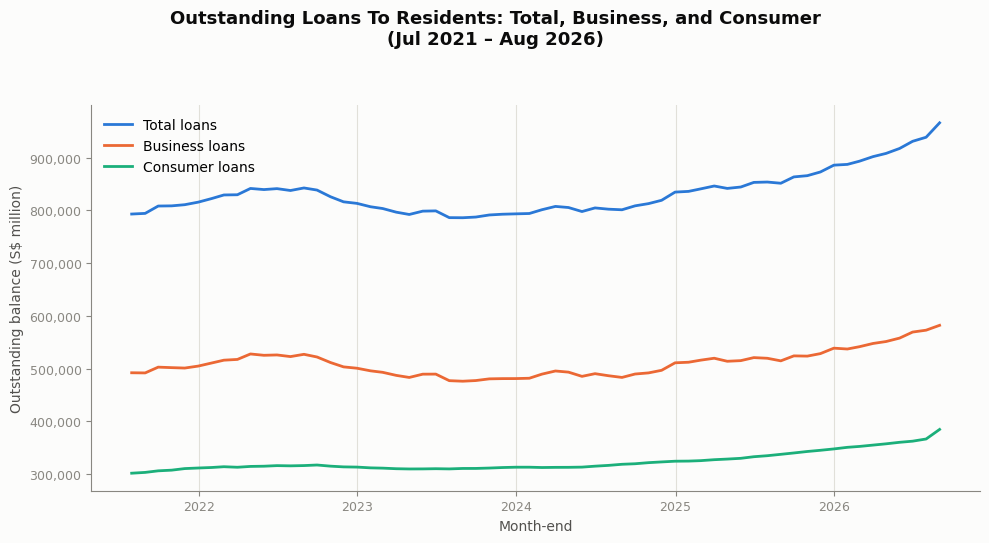

In [7]:
fig, ax = plt.subplots(figsize=(10, 5.5))
fig.patch.set_facecolor(SURFACE)

ax.plot(total_series.index, total_series.values, color=GOOD_BLUE, linewidth=2, label="Total loans")
ax.plot(biz_series.index, biz_series.values, color="#eb6834", linewidth=2, label="Business loans")
ax.plot(cons_series.index, cons_series.values, color="#1baf7a", linewidth=2, label="Consumer loans")

style_ax(ax, "Outstanding Loans To Residents: Total, Business, and Consumer\n(Jul 2021 – Aug 2026)",
         xlabel="Month-end", ylabel="Outstanding balance (S$ million)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(frameon=False, loc="upper left", fontsize=10)

fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig(FIG_DIR / "01_total_business_consumer_trends.png", dpi=150, facecolor=SURFACE)
plt.show()


## Q2 — Which of the 8 major business sectors account for the largest shares of business lending?

Shares use the reported **business lending total** (`Loans To Businesses - Total`) as the
denominator, for exactly the 8 mutually exclusive top-level business sectors — not the 11
finer sub-sector rows beneath some of them.


In [8]:
latest_sector_balances = wide.loc[LATEST_PERIOD, BUSINESS_SECTOR_IDS].sort_values(ascending=False)
latest_sector_shares = latest_sector_balances / biz_series.loc[LATEST_PERIOD] * 100

summary = pd.DataFrame({
    "sector": [name_map[s] for s in latest_sector_balances.index],
    "balance_sgd_mn": latest_sector_balances.values,
    "share_of_business_total_pct": latest_sector_shares.values,
})
display(summary)
print(f"\nCheck: shares sum to {latest_sector_shares.sum():.2f}% "
      "(should be close to 100%; small gap is published rounding, see docs/STAGE_1_DATA_INSPECTION.md Section 4).")


,sector,balance_sgd_mn,share_of_business_total_pct
0,Loans To Businesses - Building And Construction - Total,191010.6,32.818287
1,Loans To Businesses - Financial And Insurance Activities,153736.2,26.414025
2,Loans To Businesses - General Commerce - Total,102648.4,17.636428
3,"Loans To Businesses - Transport, Storage And Communicati...",51893.2,8.915976
4,Loans To Businesses - Manufacturing,30356.3,5.215636
5,Loans To Businesses - Others - Total,30200.1,5.188799
6,"Loans To Businesses - Professional, Scientific, Technica...",17492.5,3.005456
7,"Loans To Businesses - Agriculture, Mining And Quarrying ...",4687.5,0.805378



Check: shares sum to 100.00% (should be close to 100%; small gap is published rounding, see docs/STAGE_1_DATA_INSPECTION.md Section 4).


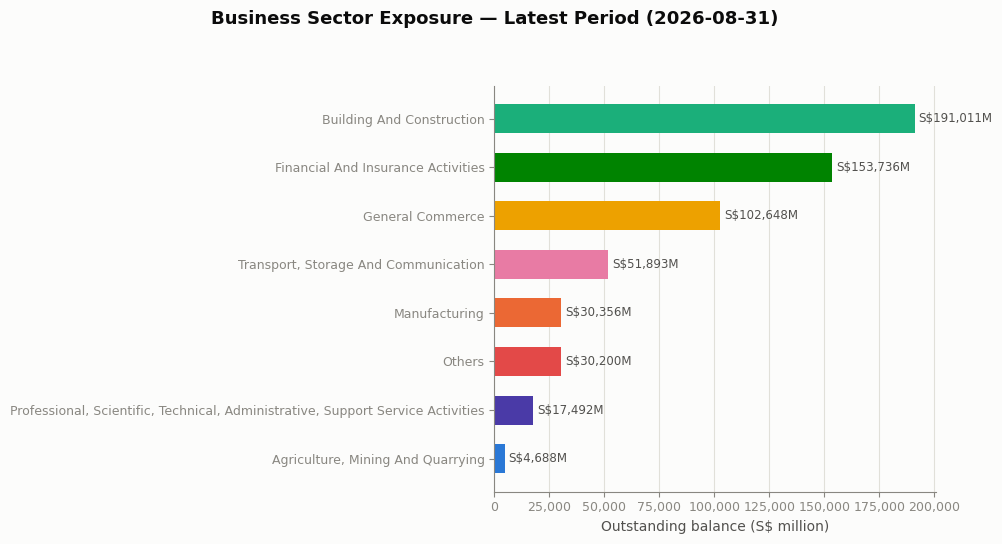

In [9]:
order = latest_sector_balances.index.tolist()
colors = [SECTOR_COLOR[s] for s in order]
labels = [short_sector_label(s) for s in order]

fig, ax = plt.subplots(figsize=(10, 5.5))
fig.patch.set_facecolor(SURFACE)

y_pos = np.arange(len(order))[::-1]
bars = ax.barh(y_pos, latest_sector_balances.values, color=colors, height=0.6)
ax.set_yticks(y_pos)
ax.set_yticklabels(labels, fontsize=9.5, color=INK_PRIMARY)

for y, val in zip(y_pos, latest_sector_balances.values):
    ax.text(val + latest_sector_balances.max() * 0.01, y, f"S${val:,.0f}M",
            va="center", fontsize=8.5, color=INK_SECONDARY)

style_ax(ax, f"Business Sector Exposure — Latest Period ({LATEST_PERIOD.date()})",
         xlabel="Outstanding balance (S$ million)")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))

fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig(FIG_DIR / "02_business_sector_ranking_latest.png", dpi=150, facecolor=SURFACE)
plt.show()


### Business sector composition: first vs. latest period

Same 8 sectors, each expressed as a share of the business lending total, comparing
Jul 2021 (first available period under the current reporting basis) to the latest
period.


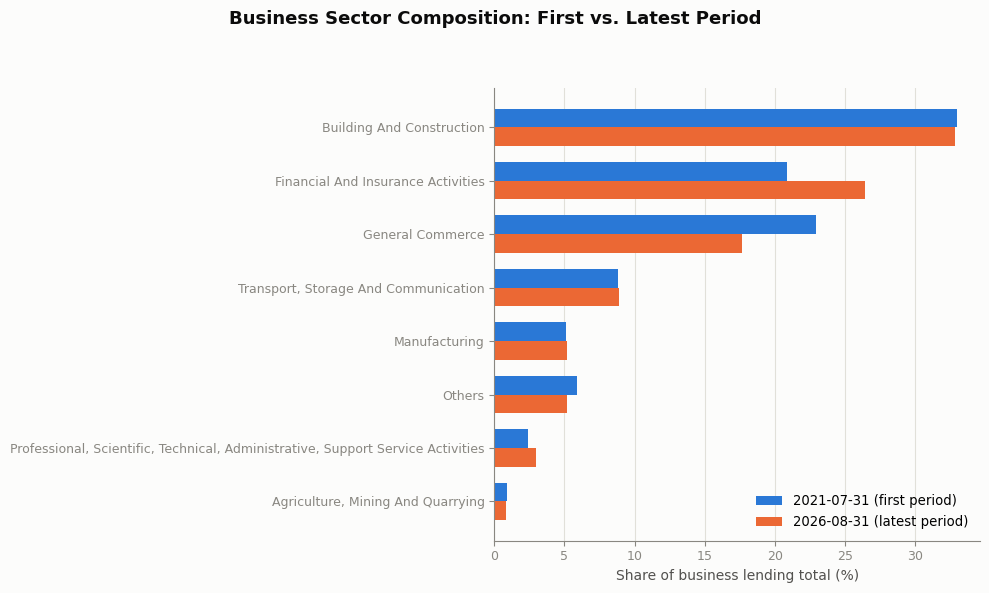

,sector,share_2021-07-31_pct,share_2026-08-31_pct,share_change_pp
0,Loans To Businesses - Building And Construction - Total,32.966795,32.818287,-0.15
1,Loans To Businesses - Financial And Insurance Activities,20.892884,26.414025,5.52
2,Loans To Businesses - General Commerce - Total,22.934967,17.636428,-5.30
3,"Loans To Businesses - Transport, Storage And Communicati...",8.826900,8.915976,0.09
4,Loans To Businesses - Manufacturing,5.083246,5.215636,0.13
5,Loans To Businesses - Others - Total,5.933838,5.188799,-0.75
6,"Loans To Businesses - Professional, Scientific, Technica...",2.420018,3.005456,0.59
7,"Loans To Businesses - Agriculture, Mining And Quarrying ...",0.941392,0.805378,-0.14


In [10]:
first_sector_shares = wide.loc[FIRST_PERIOD, BUSINESS_SECTOR_IDS] / biz_series.loc[FIRST_PERIOD] * 100
latest_sector_shares_all = wide.loc[LATEST_PERIOD, BUSINESS_SECTOR_IDS] / biz_series.loc[LATEST_PERIOD] * 100

# Order sectors by latest share for a readable chart.
order2 = latest_sector_shares_all.sort_values(ascending=False).index.tolist()
labels2 = [short_sector_label(s) for s in order2]

fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor(SURFACE)

y_pos = np.arange(len(order2))[::-1]
bar_h = 0.35
ax.barh(y_pos + bar_h / 2, first_sector_shares.loc[order2].values, height=bar_h,
        color=PERIOD_COLORS["first"], label=f"{FIRST_PERIOD.date()} (first period)")
ax.barh(y_pos - bar_h / 2, latest_sector_shares_all.loc[order2].values, height=bar_h,
        color=PERIOD_COLORS["latest"], label=f"{LATEST_PERIOD.date()} (latest period)")

ax.set_yticks(y_pos)
ax.set_yticklabels(labels2, fontsize=9.5, color=INK_PRIMARY)
style_ax(ax, "Business Sector Composition: First vs. Latest Period",
         xlabel="Share of business lending total (%)")
ax.legend(frameon=False, loc="lower right", fontsize=9.5)

fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig(FIG_DIR / "03_business_sector_composition_first_vs_latest.png", dpi=150, facecolor=SURFACE)
plt.show()

comp_table = pd.DataFrame({
    "sector": [name_map[s] for s in order2],
    f"share_{FIRST_PERIOD.date()}_pct": first_sector_shares.loc[order2].values,
    f"share_{LATEST_PERIOD.date()}_pct": latest_sector_shares_all.loc[order2].values,
})
comp_table["share_change_pp"] = (comp_table.iloc[:, 2] - comp_table.iloc[:, 1]).round(2)
display(comp_table)


## Q3 — Latest 12-month absolute and percentage changes by business sector

Comparing the latest available period to the same month 12 months earlier
(a year-over-year stock comparison, not a sum of monthly flows).


In [11]:
abs_change_12m = (wide.loc[LATEST_PERIOD, BUSINESS_SECTOR_IDS] - wide.loc[PRIOR_12M, BUSINESS_SECTOR_IDS])
pct_change_12m = pd.Series(
    safe_pct_change(wide.loc[LATEST_PERIOD, BUSINESS_SECTOR_IDS].values,
                     wide.loc[PRIOR_12M, BUSINESS_SECTOR_IDS].values),
    index=BUSINESS_SECTOR_IDS,
)

change_table = pd.DataFrame({
    "sector": [name_map[s] for s in BUSINESS_SECTOR_IDS],
    f"balance_{PRIOR_12M.date()}": wide.loc[PRIOR_12M, BUSINESS_SECTOR_IDS].values,
    f"balance_{LATEST_PERIOD.date()}": wide.loc[LATEST_PERIOD, BUSINESS_SECTOR_IDS].values,
    "abs_change_sgd_mn": abs_change_12m.values,
    "pct_change": pct_change_12m.values,
}).sort_values("abs_change_sgd_mn", ascending=False)
display(change_table)


,sector,balance_2025-08-31,balance_2026-08-31,abs_change_sgd_mn,pct_change
5,Loans To Businesses - Financial And Insurance Activities,130586.1,153736.2,23150.1,17.727844
3,Loans To Businesses - General Commerce - Total,86876.6,102648.4,15771.8,18.154256
2,Loans To Businesses - Building And Construction - Total,179211.4,191010.6,11799.2,6.583956
4,"Loans To Businesses - Transport, Storage And Communicati...",43569.1,51893.2,8324.1,19.105513
1,Loans To Businesses - Manufacturing,24779.7,30356.3,5576.6,22.504712
6,"Loans To Businesses - Professional, Scientific, Technica...",15195.6,17492.5,2296.9,15.115560
0,"Loans To Businesses - Agriculture, Mining And Quarrying ...",3309.3,4687.5,1378.2,41.646270
7,Loans To Businesses - Others - Total,31050.7,30200.1,-850.6,-2.739391


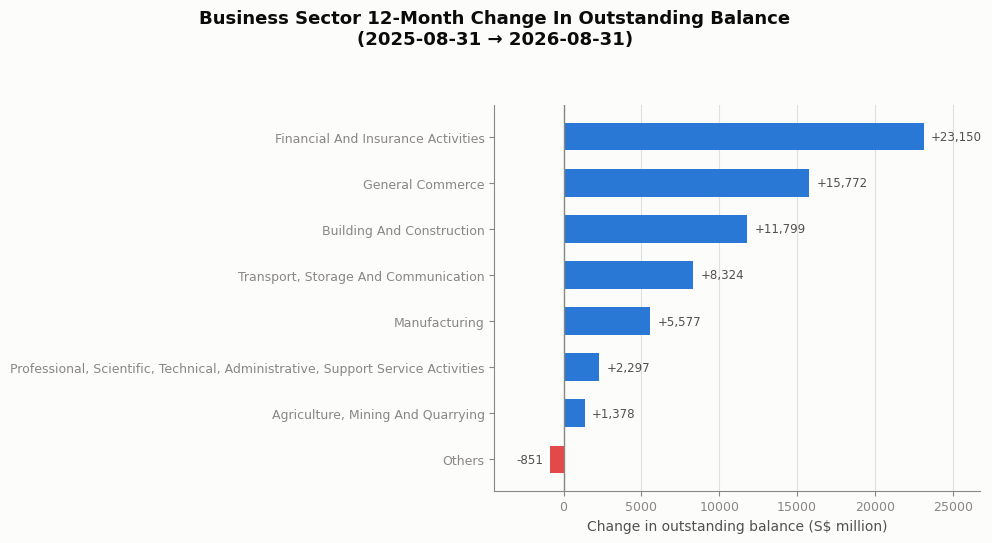

In [12]:
order3 = abs_change_12m.sort_values().index.tolist()  # ascending for a bottom-to-top horizontal bar read
labels3 = [short_sector_label(s) for s in order3]
colors3 = [GOOD_BLUE if v >= 0 else BAD_RED for v in abs_change_12m.loc[order3].values]

fig, ax = plt.subplots(figsize=(10, 5.5))
fig.patch.set_facecolor(SURFACE)
y_pos = np.arange(len(order3))
ax.barh(y_pos, abs_change_12m.loc[order3].values, color=colors3, height=0.6)
ax.axvline(0, color=INK_MUTED, linewidth=1)
ax.set_yticks(y_pos)
ax.set_yticklabels(labels3, fontsize=9.5, color=INK_PRIMARY)

data_min = min(0, abs_change_12m.min())
data_max = max(0, abs_change_12m.max())
pad = (data_max - data_min) * 0.15
ax.set_xlim(data_min - pad, data_max + pad)

for y, val in zip(y_pos, abs_change_12m.loc[order3].values):
    offset = abs_change_12m.abs().max() * 0.02
    ax.text(val + (offset if val >= 0 else -offset), y, f"{val:+,.0f}",
            va="center", ha="left" if val >= 0 else "right", fontsize=8.5, color=INK_SECONDARY)

style_ax(ax, f"Business Sector 12-Month Change In Outstanding Balance\n({PRIOR_12M.date()} → {LATEST_PERIOD.date()})",
         xlabel="Change in outstanding balance (S$ million)")
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig(FIG_DIR / "04_business_sector_absolute_change_12m.png", dpi=150, facecolor=SURFACE)
plt.show()


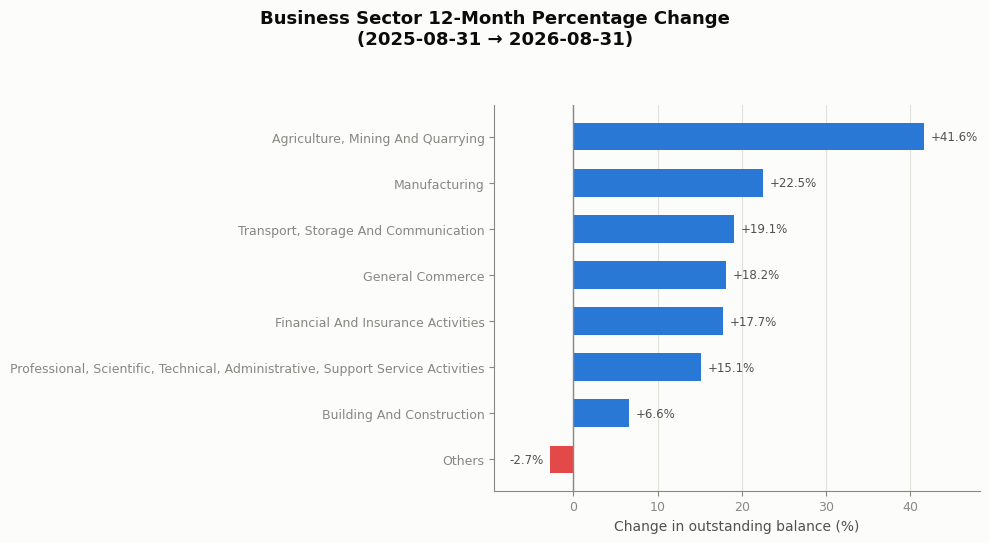

In [13]:
order4 = pct_change_12m.sort_values().index.tolist()
labels4 = [short_sector_label(s) for s in order4]
colors4 = [GOOD_BLUE if v >= 0 else BAD_RED for v in pct_change_12m.loc[order4].values]

fig, ax = plt.subplots(figsize=(10, 5.5))
fig.patch.set_facecolor(SURFACE)
y_pos = np.arange(len(order4))
ax.barh(y_pos, pct_change_12m.loc[order4].values, color=colors4, height=0.6)
ax.axvline(0, color=INK_MUTED, linewidth=1)
ax.set_yticks(y_pos)
ax.set_yticklabels(labels4, fontsize=9.5, color=INK_PRIMARY)

data_min = min(0, pct_change_12m.min())
data_max = max(0, pct_change_12m.max())
pad = (data_max - data_min) * 0.15
ax.set_xlim(data_min - pad, data_max + pad)

for y, val in zip(y_pos, pct_change_12m.loc[order4].values):
    offset = pct_change_12m.abs().max() * 0.02
    ax.text(val + (offset if val >= 0 else -offset), y, f"{val:+.1f}%",
            va="center", ha="left" if val >= 0 else "right", fontsize=8.5, color=INK_SECONDARY)

style_ax(ax, f"Business Sector 12-Month Percentage Change\n({PRIOR_12M.date()} → {LATEST_PERIOD.date()})",
         xlabel="Change in outstanding balance (%)")
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig(FIG_DIR / "05_business_sector_pct_change_12m.png", dpi=150, facecolor=SURFACE)
plt.show()


## Q4 — Has lending concentration across major business sectors increased or decreased?

**Measure used:** combined share of the **3 largest business sectors** (by outstanding
balance, re-selected each month) as a percentage of the **business lending total**
for that same month. This is a simple, transparent concentration measure — not a
modeled default-risk or credit-quality metric.


In [14]:
def top3_share(row):
    return row.sort_values(ascending=False).iloc[:3].sum()

top3_abs = wide[BUSINESS_SECTOR_IDS].apply(top3_share, axis=1)
top3_share_pct = top3_abs / biz_series * 100

concentration_first = top3_share_pct.loc[FIRST_PERIOD]
concentration_latest = top3_share_pct.loc[LATEST_PERIOD]
concentration_min = top3_share_pct.min()
concentration_max = top3_share_pct.max()

direction = "increased" if concentration_latest > concentration_first else (
    "decreased" if concentration_latest < concentration_first else "stayed flat")

print(f"Top-3 business sector concentration, {FIRST_PERIOD.date()}: {concentration_first:.2f}%")
print(f"Top-3 business sector concentration, {LATEST_PERIOD.date()}: {concentration_latest:.2f}%")
print(f"Change: {concentration_latest - concentration_first:+.2f} percentage points ({direction} over the full window)")
print(f"Range across all 62 months: {concentration_min:.2f}% to {concentration_max:.2f}%")


Top-3 business sector concentration, 2021-07-31: 76.79%
Top-3 business sector concentration, 2026-08-31: 76.87%
Change: +0.07 percentage points (increased over the full window)
Range across all 62 months: 76.56% to 79.93%


**Reading this:** the top-3 sector concentration measure moved only modestly between
the first and latest periods (see printed values above) relative to its full-sample
range. This is a descriptive observation about balance-sheet composition, not a
statement about credit risk, loss probability, or portfolio quality — the dataset
does not contain the information needed to assess those.


## Q5 — Consumer loan composition: housing/bridging, credit cards, and other categories

Shares use the reported **consumer lending total** (`Consumer Loans - Total`) as the
denominator, across exactly the 5 consumer categories.


In [15]:
first_cons_shares = wide.loc[FIRST_PERIOD, CONSUMER_CATEGORY_IDS] / cons_series.loc[FIRST_PERIOD] * 100
latest_cons_shares = wide.loc[LATEST_PERIOD, CONSUMER_CATEGORY_IDS] / cons_series.loc[LATEST_PERIOD] * 100

cons_table = pd.DataFrame({
    "category": [name_map[s] for s in CONSUMER_CATEGORY_IDS],
    f"share_{FIRST_PERIOD.date()}_pct": first_cons_shares.values,
    f"share_{LATEST_PERIOD.date()}_pct": latest_cons_shares.values,
})
cons_table["share_change_pp"] = (cons_table.iloc[:, 2] - cons_table.iloc[:, 1]).round(2)
display(cons_table.sort_values(f"share_{LATEST_PERIOD.date()}_pct", ascending=False))


,category,share_2021-07-31_pct,share_2026-08-31_pct,share_change_pp
0,Consumer Loans - Housing And Bridging Loans,69.260110,66.742532,-2.52
4,Consumer Loans - Natural Persons - Others,24.210487,25.705826,1.50
2,Consumer Loans - Natural Persons - Credit Cards,3.374703,4.674697,1.30
1,Consumer Loans - Natural Persons - Car Loans,2.778279,2.689878,-0.09
3,Consumer Loans - Natural Persons - Share Financing,0.376354,0.187067,-0.19


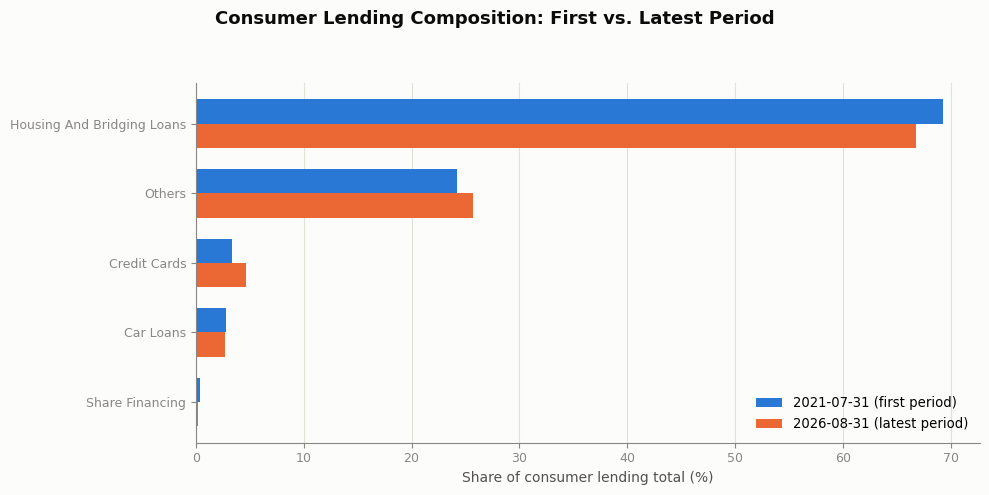

In [16]:
order5 = latest_cons_shares.sort_values(ascending=False).index.tolist()
labels5 = [short_consumer_label(s) for s in order5]

fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor(SURFACE)
y_pos = np.arange(len(order5))[::-1]
bar_h = 0.35
ax.barh(y_pos + bar_h / 2, first_cons_shares.loc[order5].values, height=bar_h,
        color=PERIOD_COLORS["first"], label=f"{FIRST_PERIOD.date()} (first period)")
ax.barh(y_pos - bar_h / 2, latest_cons_shares.loc[order5].values, height=bar_h,
        color=PERIOD_COLORS["latest"], label=f"{LATEST_PERIOD.date()} (latest period)")

ax.set_yticks(y_pos)
ax.set_yticklabels(labels5, fontsize=9.5, color=INK_PRIMARY)
style_ax(ax, "Consumer Lending Composition: First vs. Latest Period",
         xlabel="Share of consumer lending total (%)")
ax.legend(frameon=False, loc="lower right", fontsize=9.5)

fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig(FIG_DIR / "06_consumer_composition_first_vs_latest.png", dpi=150, facecolor=SURFACE)
plt.show()


## Summary

Six charts were saved to `figures/`:

1. `01_total_business_consumer_trends.png`
2. `02_business_sector_ranking_latest.png`
3. `03_business_sector_composition_first_vs_latest.png`
4. `04_business_sector_absolute_change_12m.png`
5. `05_business_sector_pct_change_12m.png`
6. `06_consumer_composition_first_vs_latest.png`

See `docs/STAGE_2_FINDINGS.md` for the five business findings written up with exact
figures, units, and periods, plus the analytical limitations that apply to all of
the above.
